Epoch: 1 Loss: 1.6957265772782932
Epoch: 2 Loss: 1.4722445956276506
Epoch: 3 Loss: 1.3667193892056986
Epoch: 4 Loss: 1.2946912240799127
Epoch: 5 Loss: 1.2290175070848002
Epoch: 6 Loss: 1.1755926185251806
Epoch: 7 Loss: 1.1244324130170487
Epoch: 8 Loss: 1.0695810650315736
Epoch: 9 Loss: 1.037090954573258
Epoch: 10 Loss: 0.9806518467795818
Epoch: 1 Loss: 1.638837512191909
Epoch: 2 Loss: 1.4396270958663862
Epoch: 3 Loss: 1.346414108715399
Epoch: 4 Loss: 1.276554124739469
Epoch: 5 Loss: 1.2167536352601502
Epoch: 6 Loss: 1.1427664180545856
Epoch: 7 Loss: 1.089156728723775
Epoch: 8 Loss: 1.0356401485555313
Epoch: 9 Loss: 0.973008859035609
Epoch: 10 Loss: 0.9323415800433634


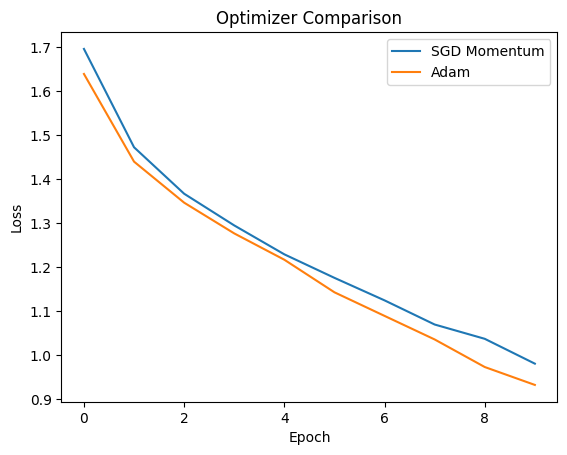

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
transform=transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.5,)*3,(0.5,)*3)])
trainset=torchvision.datasets.CIFAR10(root="./data",train=True,download=True,transform=transform)
trainloader=torch.utils.data.DataLoader(trainset,batch_size=128,shuffle=True)

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc=nn.Sequential(nn.Flatten(),nn.Linear(3072,512),nn.ReLU(),nn.Linear(512,10))
    def forward(self,x):
        return self.fc(x)

def train(model,optimizer):
    model.to(device)
    criterion=nn.CrossEntropyLoss()
    losses=[]
    for epoch in range(10):
        total=0
        for x,y in trainloader:
            x,y=x.to(device),y.to(device)
            optimizer.zero_grad()
            output=model(x)
            loss=criterion(output,y)
            loss.backward()
            optimizer.step()
            total+=loss.item()
        losses.append(total/len(trainloader))
        print("Epoch:",epoch+1,"Loss:",losses[-1])
    return losses

model1=Net()
optimizer1=optim.SGD(model1.parameters(),lr=0.01,momentum=0.9)
loss_sgd=train(model1,optimizer1)

model2=Net()
optimizer2=optim.Adam(model2.parameters(),lr=0.001)
loss_adam=train(model2,optimizer2)

plt.plot(loss_sgd,label="SGD Momentum")
plt.plot(loss_adam,label="Adam")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Optimizer Comparison")
plt.legend()
plt.show()